In [35]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True})

In [36]:
DATASETS = {
    "electricity": [
        Path("data/processed/electricity_clean"),
    ]
}
TIMESTAMP_COL = "timestamp_utc"
DEMAND_COL = "actual_load_mw"
FREQUENCY = "1h"
PLOT_TIMEZONE = "Europe/Rome"
MAX_DEMAND = None
OUTPUT_DIR = Path("quality_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

In [37]:
data = {}
problems = []
for name, paths in DATASETS.items():
    if not paths:
        raise ValueError(f"No files configured for {name}")
    frames = [pd.read_csv(path) for path in paths]
    if any(set(f.columns) != set(frames[0].columns) for f in frames):
        raise ValueError(f"Column mismatch in {name}")
    df = pd.concat(frames, ignore_index=True).replace(r"^\s*$", pd.NA, regex=True)
    if df.empty or not {TIMESTAMP_COL, DEMAND_COL}.issubset(df.columns):
        raise ValueError(f"{name}: empty data or missing required columns")
    data[name] = df
    print(f"{name}: {len(df):,} rows from {len(paths)} file(s)")
    display(df.head())

electricity: 35,064 rows from 1 file(s)


,timestamp_utc,actual_load_mw,terna_forecast_mw
0,2022-01-01T00:00:00Z,21121.0,21537.0
1,2022-01-01T01:00:00Z,19756.0,20363.0
2,2022-01-01T02:00:00Z,18685.0,18998.0
3,2022-01-01T03:00:00Z,18124.0,18639.0
4,2022-01-01T04:00:00Z,18400.0,18818.0


In [38]:
def add_problem(dataset, issue, column, start, end, count, cause, correction):
    problems.append(dict(
        dataset=dataset, issue=issue, column=column,
        start=start, end=end, number_involved=int(count),
        possible_cause=cause, proposed_correction=correction,
    ))

def report_mask(name, times, mask, issue, column, cause, correction):
    if mask.any():
        located = times[mask].dropna()
        add_problem(name, issue, column, located.min(), located.max(),
                    mask.sum(), cause, correction)

In [39]:
missing_reports = []
for name, df in data.items():
    report = pd.DataFrame({
        "dataset": name,
        "column": df.columns,
        "missing_count": df.isna().sum().to_numpy(),
        "missing_pct": df.isna().mean().mul(100).round(2).to_numpy(),
    })
    missing_reports.append(report)
missing_values_report = pd.concat(missing_reports, ignore_index=True)
display(missing_values_report)

,dataset,column,missing_count,missing_pct
0,electricity,timestamp_utc,0,0.0
1,electricity,actual_load_mw,0,0.0
2,electricity,terna_forecast_mw,1,0.0


In [40]:
parsed_times = {}
missing_hours = {}
expected_grids = {}
duplicate_counts = {}
for name, df in data.items():
    times = pd.to_datetime(df[TIMESTAMP_COL], errors="coerce", utc=True)
    parsed_times[name] = times
    invalid = df[TIMESTAMP_COL].notna() & times.isna()
    report_mask(name, times, invalid, "Unparseable timestamp", TIMESTAMP_COL,
                "Malformed value or unexpected date format.",
                "Ask the owner to verify the timestamp format and timezone.")
    counts = times.dropna().value_counts()
    duplicates = counts[counts > 1]
    duplicate_counts[name] = duplicates
    for timestamp, count in duplicates.items():
        add_problem(name, "Duplicated timestamp", TIMESTAMP_COL,
                    timestamp, timestamp, count,
                    "Possible overlapping exports or repeated ingestion.",
                    "Compare duplicate records before keeping or combining them.")
    valid = pd.DatetimeIndex(times.dropna().unique()).sort_values()
    expected = (pd.date_range(valid.min().floor(FREQUENCY),
                              valid.max().floor(FREQUENCY), freq=FREQUENCY)
                if len(valid) else pd.DatetimeIndex([], tz="UTC"))
    expected_grids[name] = expected
    missing_hours[name] = expected.difference(valid)
    off_grid = times.notna() & times.ne(times.dt.floor(FREQUENCY))
    report_mask(name, times, off_grid, "Outside hourly grid", TIMESTAMP_COL,
                "Unexpected sampling interval or timestamp alignment.",
                "Confirm the expected sampling convention before resampling.")
    print(f"{name}: {len(missing_hours[name])} absent hours; "
          f"{len(duplicates)} duplicated timestamps; "
          f"{int((duplicates - 1).sum())} extra records; "
          f"{invalid.sum()} invalid timestamps")

electricity: 0 absent hours; 0 duplicated timestamps; 0 extra records; 0 invalid timestamps


In [41]:
def consecutive_periods(timestamps):
    times = pd.DatetimeIndex(timestamps).drop_duplicates().sort_values()
    if times.empty:
        return []
    result = []
    start = previous = times[0]
    count = 1
    for current in times[1:]:
        if current - previous == pd.Timedelta(FREQUENCY):
            count += 1
        else:
            result.append((start, previous, count))
            start, count = current, 1
        previous = current
    result.append((start, previous, count))
    return result

gap_summary = []
for name, df in data.items():
    times = parsed_times[name]
    for start, end, hours in consecutive_periods(missing_hours[name]):
        add_problem(name, "Missing hourly row", "(whole row)", start, end, hours,
                    "Possible outage, export gap or missing input file.",
                    "Ask the owner to recover source records or document the gap.")
    for column in df.columns:
        missing = df[column].isna()
        unknown = missing & times.isna()
        if unknown.any():
            add_problem(name, "Missing cell with unknown time", column,
                        pd.NaT, pd.NaT, unknown.sum(),
                        "Incomplete record with unavailable or invalid timestamp.",
                        "Ask the owner to recover timestamp and missing value.")
        located = missing & times.notna()
        periods = consecutive_periods(times[located])
        for start, end, hours in periods:
            count = (located & times.between(start, end)).sum()
            add_problem(name, "Isolated NaN hour" if hours == 1 else "NaN stretch",
                        column, start, end, count,
                        "Possible incomplete record or collection outage.",
                        "Check source records; assess gap length before imputation.")
        gap_summary.append({
            "dataset": name, "column": column,
            "isolated_NaN_hours": sum(n == 1 for _, _, n in periods),
            "multi_hour_stretches": sum(n > 1 for _, _, n in periods),
            "longest_stretch_hours": max((n for _, _, n in periods), default=0),
        })
gap_summary = pd.DataFrame(gap_summary)
display(gap_summary)

,dataset,column,isolated_NaN_hours,multi_hour_stretches,longest_stretch_hours
0,electricity,timestamp_utc,0,0,0
1,electricity,actual_load_mw,0,0,0
2,electricity,terna_forecast_mw,1,0,1


In [43]:
demand_values = {}
anomaly_flags = {}
for name, df in data.items():
    times = parsed_times[name]
    demand = pd.to_numeric(df[DEMAND_COL], errors="coerce")
    invalid = df[DEMAND_COL].notna() & demand.isna()
    infinite = demand.isin([float("inf"), float("-inf")])
    report_mask(name, times, invalid, "Non-numeric demand", DEMAND_COL,
                "Text, decimal-format mismatch or undocumented missing code.",
                "Verify source formatting and missing-value conventions.")
    report_mask(name, times, infinite, "Infinite demand", DEMAND_COL,
                "Possible calculation or export error.", "Check upstream calculations.")
    finite = demand.mask(infinite)
    demand_values[name] = finite
    negative = finite.lt(0).fillna(False)
    q1, q3 = finite.quantile([0.25, 0.75])
    iqr = q3 - q1
    extreme = pd.Series(False, index=df.index)
    if pd.notna(iqr) and iqr > 0:
        extreme = (finite.lt(q1 - 3 * iqr) | finite.gt(q3 + 3 * iqr)).fillna(False)
    limit = (finite.gt(MAX_DEMAND).fillna(False) if MAX_DEMAND is not None
             else pd.Series(False, index=df.index))
    for mask, issue, cause, correction in [
        (negative, "Negative demand", "Sign error or valid net demand.",
         "Confirm whether this series measures gross or net demand."),
        (extreme, "Extreme demand: 3 x IQR", "Genuine peak, seasonality or measurement error.",
         "Compare with nearby hours, seasonal patterns and source records."),
        (limit, "Above configured demand limit", "Unit mismatch or measurement error.",
         "Verify units, configured limit and source observation."),
    ]:
        report_mask(name, times, mask, issue, DEMAND_COL, cause, correction)
    anomaly_flags[name] = negative | extreme | limit
    print(f"{name}: {int(anomaly_flags[name].sum())} demand observations flagged")

electricity: 0 demand observations flagged


In [44]:
plot_series = {}
for name in data:
    plotting = pd.DataFrame({"timestamp": parsed_times[name],
                             "demand": demand_values[name]})
    plot_series[name] = (plotting.dropna(subset=["timestamp"])
                         .groupby("timestamp")["demand"].mean().sort_index())

def save_plot(fig, name, suffix):
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{name}_{suffix}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

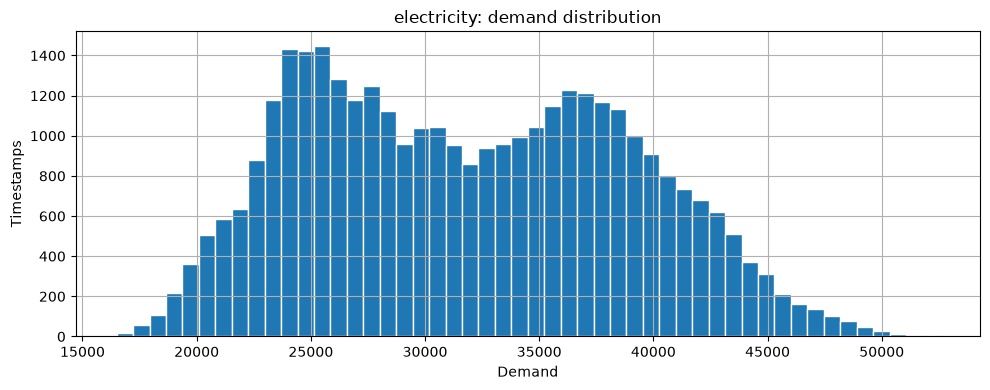

In [45]:
for name, series in plot_series.items():
    fig, ax = plt.subplots()
    ax.hist(series.dropna(), bins=50, edgecolor="white")
    ax.set(title=f"{name}: demand distribution", xlabel="Demand", ylabel="Timestamps")
    save_plot(fig, name, "01_distribution")

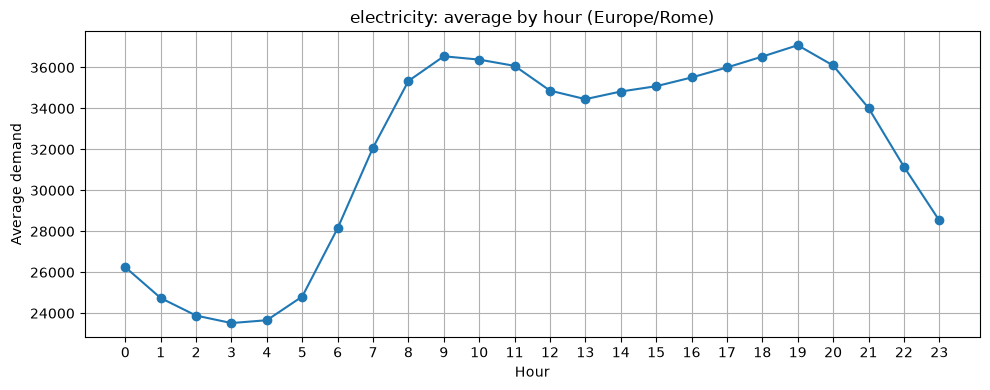

In [46]:
for name, series in plot_series.items():
    local = series.tz_convert(PLOT_TIMEZONE)
    averages = local.groupby(local.index.hour).mean().reindex(range(24))
    fig, ax = plt.subplots()
    ax.plot(averages.index, averages.values, marker="o")
    ax.set(title=f"{name}: average by hour ({PLOT_TIMEZONE})",
           xlabel="Hour", ylabel="Average demand", xticks=list(range(24)))
    save_plot(fig, name, "02_hourly_average")

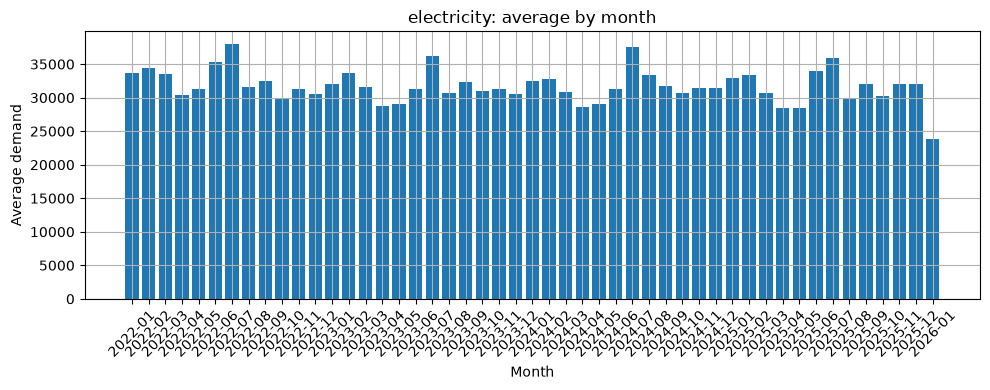

In [47]:
for name, series in plot_series.items():
    local = series.tz_convert(PLOT_TIMEZONE)
    averages = local.groupby(local.index.strftime("%Y-%m")).mean()
    fig, ax = plt.subplots()
    ax.bar(averages.index, averages.values)
    ax.set(title=f"{name}: average by month", xlabel="Month", ylabel="Average demand")
    ax.tick_params(axis="x", rotation=45)
    save_plot(fig, name, "03_monthly_average")

C:\Users\506162\AppData\Local\Temp\ipykernel_31644\295926146.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  averages = local.groupby(local.index.dayofweek).mean().reindex(range(7))


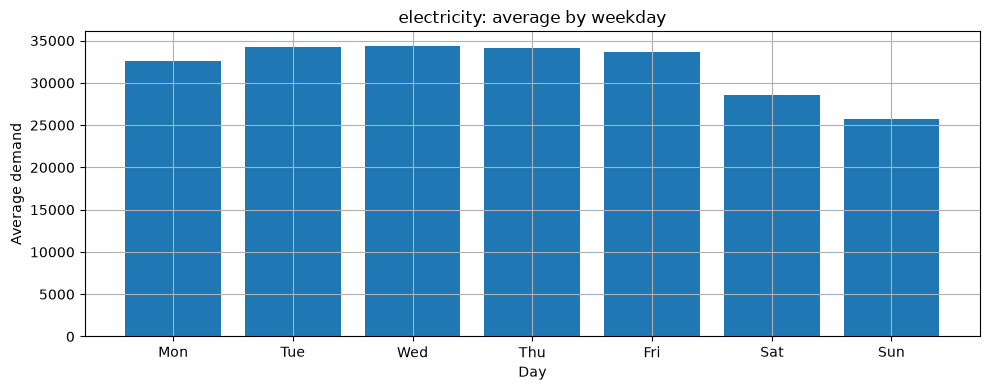

In [48]:
for name, series in plot_series.items():
    local = series.tz_convert(PLOT_TIMEZONE)
    averages = local.groupby(local.index.dayofweek).mean().reindex(range(7))
    fig, ax = plt.subplots()
    ax.bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], averages.values)
    ax.set(title=f"{name}: average by weekday", xlabel="Day", ylabel="Average demand")
    save_plot(fig, name, "04_weekday_average")

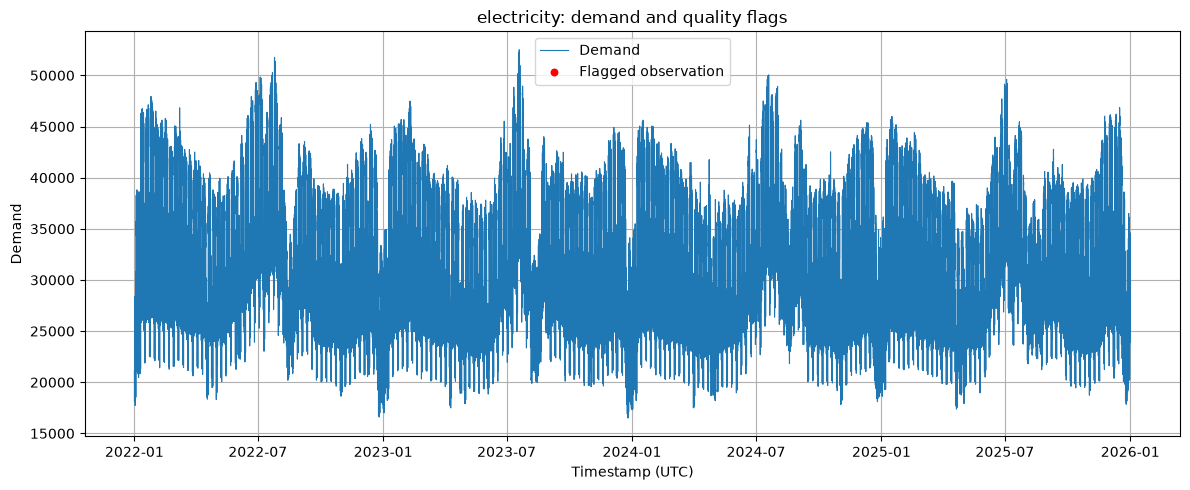

In [49]:
for name, series in plot_series.items():
    fig, ax = plt.subplots(figsize=(12, 5))
    full = series.reindex(series.index.union(expected_grids[name]).sort_values())
    ax.plot(full.index, full.values, linewidth=0.8, label="Demand")
    flags = anomaly_flags[name] & parsed_times[name].notna() & demand_values[name].notna()
    ax.scatter(parsed_times[name][flags], demand_values[name][flags],
               color="red", s=22, label="Flagged observation", zorder=3)
    absent = missing_hours[name]
    if len(absent):
        ax.scatter(absent, [0.02] * len(absent), transform=ax.get_xaxis_transform(),
                   marker="|", color="orange", label="Missing hourly row")
    ax.set(title=f"{name}: demand and quality flags", xlabel="Timestamp (UTC)", ylabel="Demand")
    ax.legend()
    save_plot(fig, name, "05_anomalies")

In [50]:
columns = ["dataset", "issue", "column", "start", "end", "number_involved",
           "possible_cause", "proposed_correction"]
problems_table = pd.DataFrame(problems, columns=columns)
missing_values_report.to_csv(OUTPUT_DIR / "missing_values_report.csv", index=False)
problems_table.to_csv(OUTPUT_DIR / "problems_table.csv", index=False)
gap_summary.to_csv(OUTPUT_DIR / "gap_summary.csv", index=False)
display(problems_table)

lines = ["DATA QUALITY REPORT", ""]
for name, df in data.items():
    times = parsed_times[name]
    lines.append(
        f"{name}: {len(df):,} rows; observed interval {times.min()} to {times.max()}; "
        f"{int(df.isna().sum().sum())} missing cells; "
        f"{len(missing_hours[name])} absent hours; "
        f"{len(duplicate_counts[name])} duplicated timestamps; "
        f"{int(anomaly_flags[name].sum())} demand observations flagged."
    )
lines += ["", "See problems_table.csv for intervals and proposed corrections.",
          "See gap_summary.csv for isolated NaN hours and consecutive stretches.",
          "Causes are hypotheses; flagged anomalies require review.",
          "Missing-cell percentages use existing rows only.",
          "No source CSV was modified. Corrections are left to the dataset owner."]
short_report = "\n".join(lines)
(OUTPUT_DIR / "short_report.txt").write_text(short_report, encoding="utf-8")
print(short_report)

,dataset,issue,column,start,end,number_involved,possible_cause,proposed_correction
0,electricity,Isolated NaN hour,terna_forecast_mw,2024-12-31 23:00:00+00:00,2024-12-31 23:00:00+00:00,1,Possible incomplete record or collection outage.,Check source records; assess gap length before...


DATA QUALITY REPORT

electricity: 35,064 rows; observed interval 2022-01-01 00:00:00+00:00 to 2025-12-31 23:00:00+00:00; 1 missing cells; 0 absent hours; 0 duplicated timestamps; 0 demand observations flagged.

See problems_table.csv for intervals and proposed corrections.
See gap_summary.csv for isolated NaN hours and consecutive stretches.
Causes are hypotheses; flagged anomalies require review.
Missing-cell percentages use existing rows only.
No source CSV was modified. Corrections are left to the dataset owner.
